# Notebook 08 — Evaluation

**Project:** A Multi-Modal Deep Learning Approach for Eggshell Micro-Crack Morphology Analysis and Root-Cause Diagnosis in Poultry Breeder Farms
**Author:** M.P.N. Sharindi (Coventry Index 16110429)
**Stage:** 08 of 12 — the analysis behind Chapter 5

---

### The result being analysed

| | test (n = 98) |
|---|---|
| four-class macro F1 | **0.7942** (per-seed 0.794 / 0.772 / 0.810, SD 0.019) |
| four-class accuracy | 0.8163 |
| binary macro F1 | 0.9070 |
| binary ROC-AUC | 0.9854 |
| binary PR-AUC | 0.9873 |

Against an acquisition floor of 0.357, a best classical pipeline of 0.565, and a human-polygon
oracle of 0.829. The test figure sits slightly above the cross-validation mean of 0.769, which is
expected rather than suspicious: the final model trained on all 554 development eggs rather than
443 per fold, and three seeds were averaged.

**No model is trained in this notebook.** Everything works from the predictions notebook 07 wrote,
so the test set is never loaded again.

### The error profile matters more than the headline

From the test confusion matrix, **one cracked egg out of 51 was called intact** — detection recall
0.980 — against eight intact eggs flagged as cracked, specificity 0.830. That asymmetry is the
right way round for a hatchery: a missed crack goes into the setter, fails to hatch, and risks
contaminating neighbouring eggs, while a false alarm costs a second look. Section 5 quantifies the
trade-off and reports the operating point rather than assuming the default threshold is correct.

### Sections

| | |
|---|---|
| 1 | Bootstrap confidence intervals — a point estimate on 98 eggs is not a result |
| 2 | McNemar against the runner-up |
| 3 | Calibration — a decision-support tool that is confidently wrong is worse than one that hedges |
| 4 | Detection operating point and the hatchery cost asymmetry |
| 5 | Error analysis gallery |
| 6 | Comparison with the literature |
| 7 | Results organised by research question |

---
## 0. Setup

In [ ]:
import os
os.environ["EGG_ARTEFACT_ROOT"] = r"D:\Eggshell-Diagnostic-Research\Artefact"

N_BOOT = 2000
RANDOM_SEED = 42

In [3]:
import sys, json, warnings
from pathlib import Path
from datetime import datetime
_here = Path.cwd()
_src = next((p / "src" for p in [_here, *_here.parents] if (p / "src" / "common").is_dir()), None)
if _src is None:
    raise RuntimeError("Run from Artefact/notebooks/ or set EGG_ARTEFACT_ROOT.")
sys.path.insert(0, str(_src))

import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import (f1_score, balanced_accuracy_score, roc_auc_score, roc_curve,
                             average_precision_score, precision_recall_curve,
                             confusion_matrix, classification_report, brier_score_loss)
from common import project_config as CFG

warnings.filterwarnings("ignore")
rng = np.random.default_rng(RANDOM_SEED)
STAGE = "08_evaluation"
OUT = CFG.results_dir(STAGE); FIG_DIR, TAB_DIR = OUT / "figures", OUT / "tables"
PROC = CFG.DATA_DIR / "processed"
PRED07 = CFG.RESULTS_DIR / "07_final_and_test" / "predictions"

splits = pd.read_csv(PROC / "splits.csv")
splits["label4"] = pd.Categorical(splits["label4"], categories=CFG.LABEL4, ordered=True)
ALL4 = [0, 1, 2, 3]
def macro4(yt, yp): return float(f1_score(yt, yp, labels=ALL4, average="macro", zero_division=0))

Z = np.load(PRED07 / "test_selected.npz")
idx, y4, y2, P = Z["idx"], Z["y4"], Z["y2"], Z["prob"]
yp = P.argmax(1); p_cracked = 1.0 - P[:, 0]
RU = None
if (PRED07 / "test_runner_up.npz").exists():
    R = np.load(PRED07 / "test_runner_up.npz")
    RU = {"yp": R["prob"].argmax(1), "p_cracked": 1.0 - R["prob"][:, 0]}
print(f"test set n = {len(y4)} | class counts "
      f"{dict(zip(CFG.LABEL4, np.bincount(y4, minlength=4)))}")
print(f"runner-up predictions available: {RU is not None}")
S = {"stage": STAGE, "generated_at": datetime.now().isoformat(timespec="seconds"),
     "n_test": int(len(y4))}

test set n = 98 | class counts {'Intact': np.int64(47), 'Hairline': np.int64(22), 'Star': np.int64(11), 'Network': np.int64(18)}
runner-up predictions available: True


---
## 1. Bootstrap confidence intervals

With 98 test eggs and only 11 of them Star, a point estimate carries real uncertainty. Percentile
bootstrap over 2000 resamples of the test set gives the interval that belongs next to every number
in Chapter 5. Wide intervals on the minority classes are a finding about the dataset, not a flaw in
the reporting, and they are stated rather than hidden.

In [4]:
def boot_ci(fn, n_boot=N_BOOT, alpha=0.05):
    n = len(y4)
    vals = []
    for _ in range(n_boot):
        b = rng.integers(0, n, n)
        if len(np.unique(y4[b])) < 2:
            continue
        vals.append(fn(b))
    vals = np.array([v for v in vals if v == v])
    return float(np.mean(vals)), float(np.percentile(vals, 100 * alpha / 2)), \
           float(np.percentile(vals, 100 * (1 - alpha / 2)))

metrics = {
    "four-class macro F1": lambda b: macro4(y4[b], yp[b]),
    "four-class balanced acc": lambda b: balanced_accuracy_score(y4[b], yp[b]),
    "four-class accuracy": lambda b: float((y4[b] == yp[b]).mean()),
    "binary macro F1": lambda b: f1_score(y2[b], (yp[b] > 0).astype(int),
                                          average="macro", zero_division=0),
    "binary ROC-AUC": lambda b: roc_auc_score(y2[b], p_cracked[b]),
    "binary PR-AUC": lambda b: average_precision_score(y2[b], p_cracked[b]),
    "detection recall": lambda b: float(((yp[b] > 0) & (y2[b] == 1)).sum()
                                        / max((y2[b] == 1).sum(), 1)),
    "detection specificity": lambda b: float(((yp[b] == 0) & (y2[b] == 0)).sum()
                                             / max((y2[b] == 0).sum(), 1)),
}
rows = []
for name, fn in metrics.items():
    point = fn(np.arange(len(y4)))
    mean, lo, hi = boot_ci(fn)
    rows.append({"metric": name, "point": round(float(point), 4),
                 "ci_low": round(lo, 4), "ci_high": round(hi, 4),
                 "ci_width": round(hi - lo, 4)})
ci = pd.DataFrame(rows).set_index("metric")
ci.to_csv(TAB_DIR / "t01_bootstrap_cis.csv")
S["bootstrap"] = ci.reset_index().to_dict("records")
print(ci.to_string())

# per class, where the minority uncertainty lives
per_rows = []
for i, lab in enumerate(CFG.LABEL4):
    n_i = int((y4 == i).sum())
    f = lambda b, i=i: f1_score((y4[b] == i).astype(int), (yp[b] == i).astype(int),
                                zero_division=0)
    point = f(np.arange(len(y4))); mean, lo, hi = boot_ci(f)
    per_rows.append({"class": lab, "n_test": n_i, "f1": round(float(point), 4),
                     "ci_low": round(lo, 4), "ci_high": round(hi, 4),
                     "ci_width": round(hi - lo, 4)})
per = pd.DataFrame(per_rows).set_index("class")
per.to_csv(TAB_DIR / "t02_per_class_cis.csv")
S["per_class"] = per.reset_index().to_dict("records")
print()
print(per.to_string())
print(f"\nThe Star interval is the widest because only {int((y4==2).sum())} Star eggs are in the")
print("test set. Quote the interval, not the point estimate, whenever that class is discussed.")

                          point  ci_low  ci_high  ci_width
metric                                                    
four-class macro F1      0.7942  0.6981   0.8761    0.1779
four-class balanced acc  0.8110  0.7173   0.8975    0.1802
four-class accuracy      0.8163  0.7347   0.8878    0.1531
binary macro F1          0.9070  0.8456   0.9588    0.1131
binary ROC-AUC           0.9854  0.9654   0.9974    0.0320
binary PR-AUC            0.9873  0.9687   0.9978    0.0291
detection recall         0.9804  0.9344   1.0000    0.0656
detection specificity    0.8298  0.7111   0.9286    0.2175

          n_test      f1  ci_low  ci_high  ci_width
class                                              
Intact        47  0.8966  0.8192   0.9574    0.1382
Hairline      22  0.7200  0.5555   0.8421    0.2866
Star          11  0.7826  0.5455   0.9444    0.3990
Network       18  0.7778  0.5926   0.9091    0.3165

The Star interval is the widest because only 11 Star eggs are in the
test set. Quote the interva

---
## 2. McNemar against the runner-up

In [5]:
if RU is not None:
    a_ok = (yp == y4); b_ok = (RU["yp"] == y4)
    n01 = int((a_ok & ~b_ok).sum()); n10 = int((~a_ok & b_ok).sum())
    tab = np.array([[int((a_ok & b_ok).sum()), n01], [n10, int((~a_ok & ~b_ok).sum())]])
    # exact binomial test: the chi-square approximation is unreliable at these counts
    p_exact = float(stats.binomtest(n01, n01 + n10, 0.5).pvalue) if (n01 + n10) else 1.0
    mc = {"selected_correct_runner_wrong": n01, "runner_correct_selected_wrong": n10,
          "discordant_pairs": n01 + n10, "p_exact_binomial": round(p_exact, 4),
          "selected_acc": round(float(a_ok.mean()), 4),
          "runner_up_acc": round(float(b_ok.mean()), 4)}
    S["mcnemar"] = mc
    print(pd.DataFrame(tab, index=["selected correct", "selected wrong"],
                       columns=["runner correct", "runner wrong"]).to_string())
    print(f"\n{json.dumps(mc, indent=2)}")
    print(f"\nWith {n01 + n10} discordant pairs the test has very little power. Report it as")
    print("'no significant difference' rather than as evidence the two are equivalent.")
else:
    print("runner-up predictions not found; skipping McNemar")

                  runner correct  runner wrong
selected correct              78             2
selected wrong                 3            15

{
  "selected_correct_runner_wrong": 2,
  "runner_correct_selected_wrong": 3,
  "discordant_pairs": 5,
  "p_exact_binomial": 1.0,
  "selected_acc": 0.8163,
  "runner_up_acc": 0.8265
}

With 5 discordant pairs the test has very little power. Report it as
'no significant difference' rather than as evidence the two are equivalent.


---
## 3. Calibration

The dashboard shows a root-cause attribution derived from the predicted pattern. If the model is
confidently wrong, the farm manager acts on a confident wrong recommendation. Expected calibration
error and a reliability curve say whether the reported confidence can be trusted at all, which is a
requirement for a decision-support artefact and not an optional extra.

In [6]:
def ece(prob, correct, n_bins=10):
    conf = prob.max(1); edges = np.linspace(0, 1, n_bins + 1)
    e, rows = 0.0, []
    for i in range(n_bins):
        m = (conf > edges[i]) & (conf <= edges[i + 1])
        if m.sum() == 0:
            continue
        acc = float(correct[m].mean()); cf = float(conf[m].mean())
        e += m.mean() * abs(acc - cf)
        rows.append({"bin": f"{edges[i]:.1f}-{edges[i+1]:.1f}", "n": int(m.sum()),
                     "mean_confidence": round(cf, 3), "accuracy": round(acc, 3)})
    return float(e), pd.DataFrame(rows)

correct = (yp == y4).astype(float)
ECE, rel = ece(P, correct)
brier = float(np.mean([brier_score_loss((y4 == i).astype(int), P[:, i]) for i in ALL4]))
S["calibration"] = {"ece": round(ECE, 4), "mean_brier": round(brier, 4),
                    "mean_confidence": round(float(P.max(1).mean()), 4),
                    "accuracy": round(float(correct.mean()), 4)}
print(rel.to_string(index=False))
print(f"\nECE {ECE:.4f} | mean Brier {brier:.4f} | mean confidence "
      f"{P.max(1).mean():.3f} vs accuracy {correct.mean():.3f}")
print("Mean confidence above accuracy means over-confidence; below means under-confidence.")
rel.to_csv(TAB_DIR / "t03_reliability.csv", index=False)

    bin  n  mean_confidence  accuracy
0.3-0.4  1            0.351     1.000
0.4-0.5  3            0.468     0.333
0.5-0.6 11            0.539     0.273
0.6-0.7 13            0.665     0.462
0.7-0.8  3            0.776     0.667
0.8-0.9 14            0.869     1.000
0.9-1.0 53            0.964     1.000

ECE 0.1093 | mean Brier 0.0536 | mean confidence 0.836 vs accuracy 0.816
Mean confidence above accuracy means over-confidence; below means under-confidence.


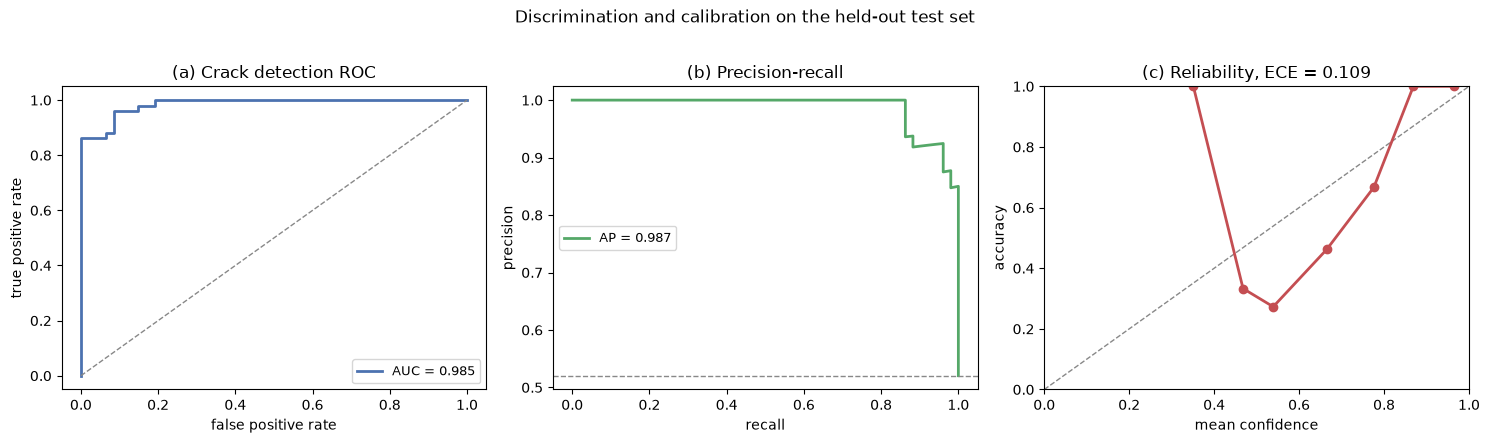

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
ax = axes[0]
fpr, tpr, _ = roc_curve(y2, p_cracked)
ax.plot(fpr, tpr, lw=2, color="#4C72B0",
        label=f"AUC = {roc_auc_score(y2, p_cracked):.3f}")
ax.plot([0, 1], [0, 1], ls="--", color="#888", lw=1)
ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
ax.set_title("(a) Crack detection ROC"); ax.legend(fontsize=9)

ax = axes[1]
pr, rc, _ = precision_recall_curve(y2, p_cracked)
ax.plot(rc, pr, lw=2, color="#55A868",
        label=f"AP = {average_precision_score(y2, p_cracked):.3f}")
ax.axhline(y2.mean(), ls="--", color="#888", lw=1)
ax.set_xlabel("recall"); ax.set_ylabel("precision")
ax.set_title("(b) Precision-recall"); ax.legend(fontsize=9)

ax = axes[2]
ax.plot([0, 1], [0, 1], ls="--", color="#888", lw=1)
if len(rel):
    ax.plot(rel["mean_confidence"], rel["accuracy"], "o-", lw=2, color="#C44E52")
ax.set_xlabel("mean confidence"); ax.set_ylabel("accuracy")
ax.set_title(f"(c) Reliability, ECE = {ECE:.3f}")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
fig.suptitle("Discrimination and calibration on the held-out test set", y=1.02, fontsize=12)
fig.tight_layout(); fig.savefig(FIG_DIR / "01_curves.png", bbox_inches="tight")
plt.show()

---
## 4. Operating point

The default decision rule is argmax, which implicitly treats a missed crack and a false alarm as
equally costly. In a hatchery they are not. A cracked egg set for incubation fails and can
contaminate neighbouring eggs; a flagged intact egg costs one manual check. The table below sweeps
the detection threshold so that Chapter 6 can recommend an operating point on stated grounds rather
than inherit one by default.

In [8]:
rows = []
for t in np.arange(0.05, 0.96, 0.05):
    pred = (p_cracked >= t).astype(int)
    tp = int(((pred == 1) & (y2 == 1)).sum()); fn = int(((pred == 0) & (y2 == 1)).sum())
    fp = int(((pred == 1) & (y2 == 0)).sum()); tn = int(((pred == 0) & (y2 == 0)).sum())
    rows.append({"threshold": round(float(t), 2), "recall": round(tp / max(tp + fn, 1), 3),
                 "specificity": round(tn / max(tn + fp, 1), 3),
                 "precision": round(tp / max(tp + fp, 1), 3),
                 "missed_cracks": fn, "false_alarms": fp,
                 "f1": round(float(f1_score(y2, pred, zero_division=0)), 3)})
op = pd.DataFrame(rows).set_index("threshold")
op.to_csv(TAB_DIR / "t04_operating_points.csv")
S["operating_points"] = op.reset_index().to_dict("records")
print(op.to_string())
zero_miss = op[op["missed_cracks"] == 0]
if len(zero_miss):
    t0 = zero_miss.index.max()
    print(f"\nhighest threshold with ZERO missed cracks: {t0} "
          f"(false alarms {int(zero_miss.loc[t0, 'false_alarms'])} of {int((y2==0).sum())} intact)")
    S["zero_miss_threshold"] = float(t0)
print("\nargmax corresponds to threshold 0.50. Chapter 6 should recommend an operating point")
print("explicitly, with the cost argument stated, rather than leaving the default unexamined.")

           recall  specificity  precision  missed_cracks  false_alarms     f1
threshold                                                                    
0.05        1.000        0.426      0.654              0            27  0.791
0.10        1.000        0.574      0.718              0            20  0.836
0.15        1.000        0.702      0.785              0            14  0.879
0.20        1.000        0.723      0.797              0            13  0.887
0.25        1.000        0.766      0.823              0            11  0.903
0.30        1.000        0.766      0.823              0            11  0.903
0.35        0.980        0.809      0.847              1             9  0.909
0.40        0.980        0.809      0.847              1             9  0.909
0.45        0.980        0.809      0.847              1             9  0.909
0.50        0.980        0.809      0.847              1             9  0.909
0.55        0.980        0.809      0.847              1        

---
## 5. Error analysis

In [9]:
cache = np.load(PROC / f"cache_neutral_fill_448.npy", mmap_mode="r")
test_rows = splits.index[splits["split"].eq("test")].to_numpy()
pos = {int(r): i for i, r in enumerate(np.sort(test_rows))}
wrong = np.where(yp != y4)[0]
print(f"{len(wrong)} of {len(y4)} test eggs misclassified\n")

err = pd.DataFrame({
    "egg_id": [splits.loc[int(idx[i]), "egg_id"] for i in wrong],
    "annotated": [CFG.LABEL4[y4[i]] for i in wrong],
    "predicted": [CFG.LABEL4[yp[i]] for i in wrong],
    "confidence": [round(float(P[i].max()), 3) for i in wrong],
    "age_class": [splits.loc[int(idx[i]), "age_class"] for i in wrong],
    "capture_block": [splits.loc[int(idx[i]), "capture_block"] for i in wrong],
}).sort_values("confidence", ascending=False)
err.to_csv(TAB_DIR / "t05_misclassified.csv", index=False)
S["errors"] = err.to_dict("records")
print(err.to_string(index=False))

pair = err.groupby(["annotated", "predicted"]).size().sort_values(ascending=False)
print("\nmost common confusions:")
print(pair.to_string())

18 of 98 test eggs misclassified

egg_id annotated predicted  confidence       age_class  capture_block
  E437   Network  Hairline       0.779 Peak production              6
  E395  Hairline   Network       0.678 Peak production              6
  E402      Star  Hairline       0.675        Late lay              6
  E649  Hairline    Intact       0.668       Early lay              9
  E465    Intact  Hairline       0.660        Late lay              7
  E353   Network      Star       0.642 Peak production              5
  E194  Hairline      Star       0.631 Peak production              2
  E021    Intact  Hairline       0.631        Late lay              0
  E640    Intact  Hairline       0.577       Early lay              9
  E340  Hairline   Network       0.557       Early lay              5
  E536    Intact   Network       0.549 Peak production              8
  E451    Intact  Hairline       0.543       Early lay              6
  E267      Star   Network       0.525        Late lay  

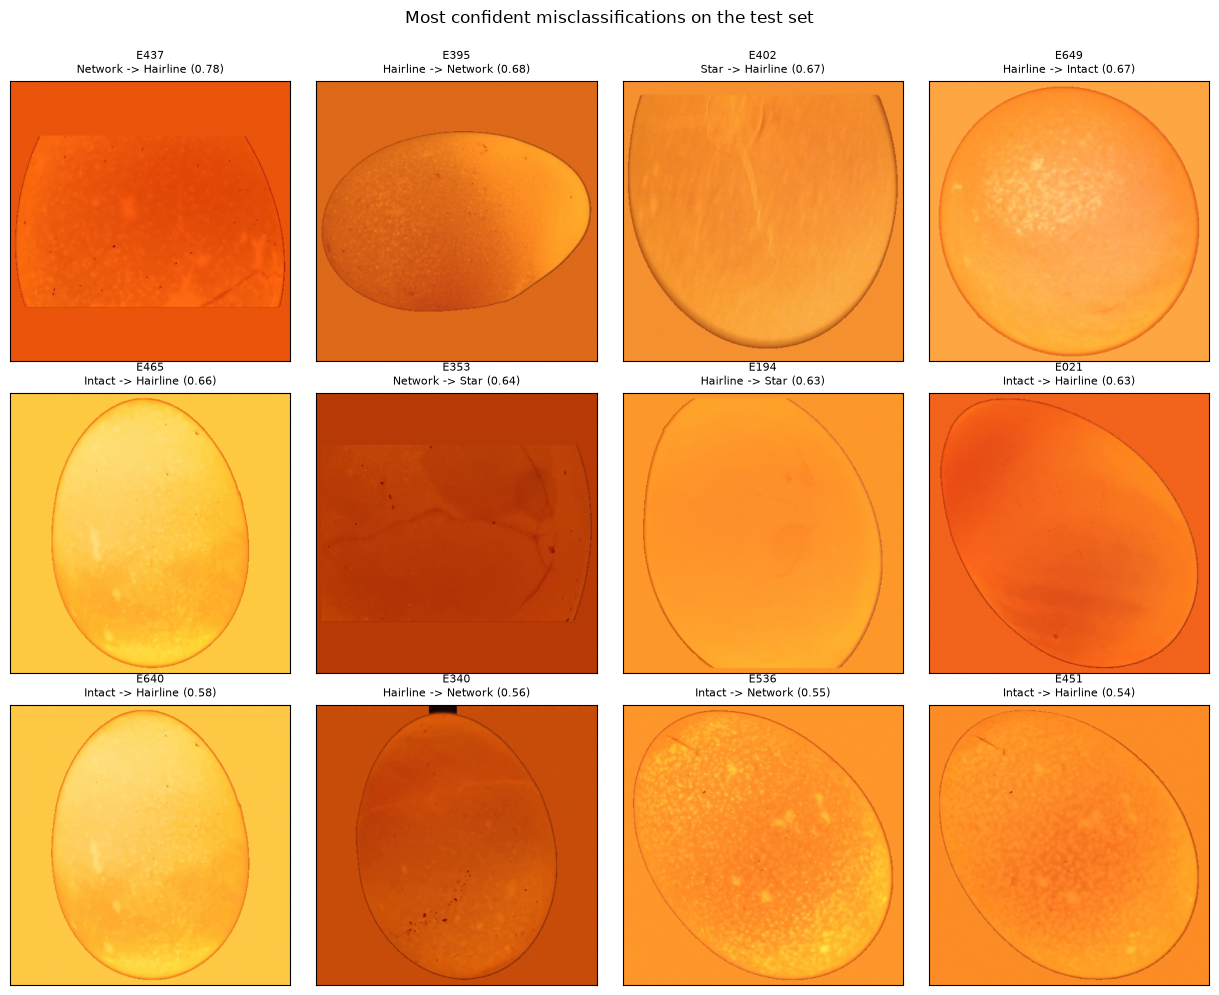

Inspect these before writing Section 5. A confident error on an egg whose annotation
is arguable is a different finding from a confident error on an unambiguous one.


In [10]:
n = min(12, len(wrong))
if n:
    cols = 4; rws = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rws, cols, figsize=(3.1 * cols, 3.3 * rws))
    axes = np.atleast_1d(axes).ravel()
    sel = wrong[np.argsort(-P[wrong].max(1))][:n]      # most confident errors first
    for ax, i in zip(axes, sel):
        r = int(idx[i])
        ax.imshow(np.asarray(cache[r]))
        ax.set_title(f"{splits.loc[r, 'egg_id']}\n{CFG.LABEL4[y4[i]]} -> "
                     f"{CFG.LABEL4[yp[i]]} ({P[i].max():.2f})", fontsize=8)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for ax in axes[n:]:
        ax.axis("off")
    fig.suptitle("Most confident misclassifications on the test set", y=1.0, fontsize=12)
    fig.tight_layout(); fig.savefig(FIG_DIR / "02_error_gallery.png", bbox_inches="tight")
    plt.show()
    print("Inspect these before writing Section 5. A confident error on an egg whose annotation")
    print("is arguable is a different finding from a confident error on an unambiguous one.")

---
## 6. Comparison with the literature, and results by research question

In [11]:
lit = pd.DataFrame([
    {"study": "Cengel et al. (2025)", "task": "intact vs damaged (binary)",
     "reported": "98.73% accuracy", "morphology": "no", "metadata": "no",
     "explainability validated": "no", "leakage screened": "no"},
    {"study": "Cheng et al. (2024)", "task": "cracked egg detection (binary)",
     "reported": "88.8% mAP", "morphology": "no", "metadata": "no",
     "explainability validated": "no", "leakage screened": "no"},
    {"study": "This work", "task": "4-class morphology + detection",
     "reported": f"{macro4(y4, yp):.3f} macro F1 / "
                 f"{f1_score(y2, (yp>0).astype(int), average='macro', zero_division=0):.3f} binary",
     "morphology": "yes (3 types)", "metadata": "yes (decision layer)",
     "explainability validated": "nb 09", "leakage screened": "yes"},
]).set_index("study")
lit.to_csv(TAB_DIR / "t06_literature_comparison.csv")
print(lit.to_string())
print("""
Do NOT present 0.794 as beating 98.73%. The tasks are different: Cengel et al. classify visibly
damaged eggs into two classes on a larger dataset, this work resolves three crack morphologies on
652 candled breeder eggs and reports macro F1 under class imbalance. The comparable number here is
binary detection, and the meaningful comparison is the capability axis, not the accuracy axis.""")

by_rq = pd.DataFrame([
    {"RQ": "RQ1 detection", "result": f"macro F1 {f1_score(y2,(yp>0).astype(int),average='macro',zero_division=0):.3f}, "
                                      f"ROC-AUC {roc_auc_score(y2,p_cracked):.3f}, recall "
                                      f"{((yp>0)&(y2==1)).sum()/max((y2==1).sum(),1):.3f}"},
    {"RQ": "RQ2 morphology", "result": f"macro F1 {macro4(y4,yp):.3f}, accuracy {(y4==yp).mean():.3f}"},
    {"RQ": "RQ3 metadata fusion", "result": "no gain; paired diff -0.0046 ± 0.0420 (nb 06)"},
    {"RQ": "RQ4 explanation localisation", "result": "notebook 09"},
    {"RQ": "RQ5 root-cause propagation", "result": "notebook 10"},
    {"RQ": "RQ6 usability", "result": "notebook 12"},
]).set_index("RQ")
by_rq.to_csv(TAB_DIR / "t07_results_by_rq.csv")
print()
print(by_rq.to_string())

def _safe(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    return str(o)
(OUT / "evaluation_summary.json").write_text(json.dumps(S, indent=2, default=_safe))

L = ["=" * 70, "NOTEBOOK 08 DIGEST -- EVALUATION", "=" * 70,
     f"generated: {S['generated_at']}  |  n_test = {S['n_test']}", "",
     "BOOTSTRAP 95% CONFIDENCE INTERVALS"]
for r in S["bootstrap"]:
    L.append(f"   {r['metric']:<26s} {r['point']:.4f}  [{r['ci_low']:.4f}, {r['ci_high']:.4f}]")
L += ["", "PER CLASS"]
for r in S["per_class"]:
    L.append(f"   {r['class']:<9s} n={r['n_test']:<3d} F1 {r['f1']:.4f}  "
             f"[{r['ci_low']:.4f}, {r['ci_high']:.4f}]")
if "mcnemar" in S:
    L += ["", f"McNEMAR vs runner-up: {S['mcnemar']}"]
L += ["", f"CALIBRATION: {S['calibration']}"]
if "zero_miss_threshold" in S:
    L.append(f"zero-missed-crack threshold: {S['zero_miss_threshold']}")
L += ["", f"ERRORS: {len(S['errors'])} misclassified of {S['n_test']}", "=" * 70]
digest = "\n".join(L)
(OUT / "digest.txt").write_text(digest)
print(digest)

                                                task                       reported     morphology              metadata explainability validated leakage screened
study                                                                                                                                                             
Cengel et al. (2025)      intact vs damaged (binary)                98.73% accuracy             no                    no                       no               no
Cheng et al. (2024)   cracked egg detection (binary)                      88.8% mAP             no                    no                       no               no
This work             4-class morphology + detection  0.794 macro F1 / 0.907 binary  yes (3 types)  yes (decision layer)                    nb 09              yes

Do NOT present 0.794 as beating 98.73%. The tasks are different: Cengel et al. classify visibly
damaged eggs into two classes on a larger dataset, this work resolves three crack morpho